# EN3160 ASSIGNMENT 03
## CONVOLUTIONAL NEURAL NETWORKS

**Name:** M.R.A.Hakam  
**Index number:** 230224V

### QUESTION 1  DENSE NETWORK

The network takes 3072 image values, uses 100 sigmoid hidden units and gives 10 output scores. Cross entropy replaces the squared error loss in the starting code

The forward pass, gradients and parameter updates are written directly with tensor operations. The loss uses logsumexp to avoid numerical problems with the output scores. All gradients are calculated before changing either weight matrix

In [1]:
import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchvision
from torch.utils.data import DataLoader
from torchvision import transforms


ROOT = Path.cwd()


#### NETWORK

The starting weights use standard deviation 1 divided by the square root of the number of inputs to each layer

In [2]:
class DenseNetwork:
    def __init__(self, input_size=3072, hidden_size=100, classes=10, seed=0):
        generator = torch.Generator().manual_seed(seed)
        self.w1 = torch.randn(input_size, hidden_size, generator=generator) / input_size**0.5
        self.b1 = torch.zeros(hidden_size)
        self.w2 = torch.randn(hidden_size, classes, generator=generator) / hidden_size**0.5
        self.b2 = torch.zeros(classes)

    def forward(self, inputs):
        hidden = torch.sigmoid(inputs @ self.w1 + self.b1)
        logits = hidden @ self.w2 + self.b2
        return hidden, logits

    def gradients(self, inputs, labels):
        hidden, logits = self.forward(inputs)
        log_probabilities = logits - torch.logsumexp(logits, dim=1, keepdim=True)
        rows = torch.arange(len(labels))
        loss = -log_probabilities[rows, labels].mean()
        output_gradient = log_probabilities.exp()
        output_gradient[rows, labels] -= 1
        output_gradient /= len(labels)

        dw2 = hidden.T @ output_gradient
        db2 = output_gradient.sum(dim=0)
        hidden_gradient = (output_gradient @ self.w2.T) * hidden * (1 - hidden)
        dw1 = inputs.T @ hidden_gradient
        db1 = hidden_gradient.sum(dim=0)
        return loss, (dw1, db1, dw2, db2)

    def update(self, gradients, learning_rate):
        dw1, db1, dw2, db2 = gradients
        self.w1 -= learning_rate * dw1
        self.b1 -= learning_rate * db1
        self.w2 -= learning_rate * dw2
        self.b2 -= learning_rate * db2


#### DATA AND TRAINING SETTINGS

The CIFAR10 training set contains 50000 images and the test set contains 10000 images. The images are scaled with mean 0.5 and standard deviation 0.5 in each colour channel

Training uses batches of 50, seed 0 and 10 full epochs. The starting learning rate is 0.1 and it is multiplied by 0.9 after each epoch. The learning rate and starting weights were changed to suit the hidden layer and cross entropy loss

In [3]:
def create_dense_loaders(batch_size=50, seed=0):
    transform = transforms.Compose(
        [transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
    )
    trainset = torchvision.datasets.CIFAR10(
        root=ROOT / "data", train=True, download=True, transform=transform
    )
    testset = torchvision.datasets.CIFAR10(
        root=ROOT / "data", train=False, download=True, transform=transform
    )
    generator = torch.Generator().manual_seed(seed)
    trainloader = DataLoader(
        trainset, batch_size=batch_size, shuffle=True, generator=generator, num_workers=0
    )
    train_eval_loader = DataLoader(trainset, batch_size=batch_size, num_workers=0)
    testloader = DataLoader(testset, batch_size=batch_size, num_workers=0)
    return trainloader, train_eval_loader, testloader


#### LOSS AND ACCURACY

Training and test loss and accuracy are measured on the full sets after each epoch. The test set is used for evaluation and does not update the weights

In [4]:
@torch.no_grad()
def evaluate_dense(model, loader):
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        _, logits = model.forward(images.flatten(start_dim=1))
        log_probabilities = logits - torch.logsumexp(logits, dim=1, keepdim=True)
        total_loss -= log_probabilities[torch.arange(len(labels)), labels].sum().item()
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += len(labels)
    return total_loss / total, 100.0 * correct / total


In [5]:
def save_dense_history(history, settings):
    output_dir = ROOT / "results" / "q1"
    output_dir.mkdir(parents=True, exist_ok=True)
    with (output_dir / "history.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    dense_result = {
        **settings,
        "completed_epochs": len(history),
        "final_metrics": history[-1],
        "history": history,
    }
    (output_dir / "training_results.json").write_text(
        json.dumps(dense_result, indent=2) + "\n", encoding="utf-8"
    )

    epochs = [row["epoch"] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
    axes[0].plot(epochs, [row["train_loss"] for row in history], marker="o", label="Training")
    axes[0].plot(epochs, [row["test_loss"] for row in history], marker="o", label="Test")
    axes[0].set(xlabel="Epoch", ylabel="Cross entropy loss", title="Loss after each epoch")
    axes[1].plot(epochs, [row["train_accuracy"] for row in history], marker="o", label="Training")
    axes[1].plot(epochs, [row["test_accuracy"] for row in history], marker="o", label="Test")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Accuracy after each epoch")
    for axis in axes:
        axis.set_xticks(epochs)
        axis.grid(alpha=0.2)
        axis.legend()
    fig.savefig(output_dir / "training_curve.png", dpi=180)
    plt.close(fig)
    return dense_result


#### TRAINING

Each batch is passed through the network and the gradients are calculated manually. The weights and biases are updated using those gradients before the next batch is processed

In [6]:
def train_dense_network(epochs=10, batch_size=50, learning_rate=0.1, lr_decay=0.9, seed=0):
    if epochs < 1 or batch_size < 1 or learning_rate <= 0 or not 0 < lr_decay <= 1:
        raise ValueError("Invalid training settings")
    torch.set_num_threads(4)
    torch.manual_seed(seed)
    trainloader, train_eval_loader, testloader = create_dense_loaders(batch_size, seed)
    model = DenseNetwork(seed=seed)
    history = []
    settings = {
        "dataset": "CIFAR10",
        "training_samples": len(trainloader.dataset),
        "test_samples": len(testloader.dataset),
        "input_size": 3072,
        "hidden_size": 100,
        "output_size": 10,
        "hidden_activation": "sigmoid",
        "loss": "cross entropy",
        "gradients": "manual",
        "initialization": "normal with standard deviation equal to 1 / sqrt(fan_in)",
        "normalization_mean": [0.5, 0.5, 0.5],
        "normalization_std": [0.5, 0.5, 0.5],
        "data_type": "float32",
        "training_shuffle": True,
        "epochs": epochs,
        "batch_size": batch_size,
        "initial_learning_rate": learning_rate,
        "learning_rate_decay": lr_decay,
        "seed": seed,
        "device": "cpu",
        "torch_threads": 4,
        "torch_version": torch.__version__,
        "torchvision_version": torchvision.__version__,
        "python_version": sys.version.split()[0],
        "accuracy_units": "percent",
    }
    for epoch in range(1, epochs + 1):
        for images, labels in trainloader:
            inputs = images.flatten(start_dim=1)
            loss, gradients = model.gradients(inputs, labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Training loss is not finite")
            model.update(gradients, learning_rate)
        train_loss, train_accuracy = evaluate_dense(model, train_eval_loader)
        test_loss, test_accuracy = evaluate_dense(model, testloader)
        history.append(
            {
                "epoch": epoch,
                "learning_rate": learning_rate,
                "train_loss": train_loss,
                "train_accuracy": train_accuracy,
                "test_loss": test_loss,
                "test_accuracy": test_accuracy,
            }
        )
        save_dense_history(history, settings)
        print(
            f"Epoch {epoch} of {epochs}: training accuracy {train_accuracy:.2f}%, "
            f"test accuracy {test_accuracy:.2f}%, training loss {train_loss:.4f}, "
            f"test loss {test_loss:.4f}",
            flush=True,
        )
        learning_rate *= lr_decay

    checkpoint = {
        "w1": model.w1,
        "b1": model.b1,
        "w2": model.w2,
        "b2": model.b2,
        "settings": settings,
    }
    torch.save(checkpoint, ROOT / "results" / "q1" / "dense_weights.pt")
    return {**settings, "final_metrics": history[-1], "history": history}


In [7]:
import contextlib
import io

with contextlib.redirect_stdout(io.StringIO()):
    dense_result = train_dense_network()


#### RESULTS

In [8]:
print(f"Training accuracy after 10 epochs: {dense_result['final_metrics']['train_accuracy']:.2f}%")
print(f"Test accuracy after 10 epochs: {dense_result['final_metrics']['test_accuracy']:.2f}%")


Training accuracy after 10 epochs: 53.17%
Test accuracy after 10 epochs: 48.31%


After 10 epochs the training accuracy is 53.17% and the test accuracy is 48.31%. The training accuracy is 4.86 percentage points higher than the test accuracy


### QUESTION 2(A)  LENET5 ON MNIST

The MNIST images are padded by two pixels on each side to give 32 by 32 inputs. LeNet5 uses convolution layers with 6, 16 and 120 output channels, tanh activations and average pooling. The final fully connected layers have 84 units and 10 output scores

Training uses all 60000 training images and evaluation uses all 10000 test images. The settings are 10 epochs, batch size 50, Adam with learning rate 0.001 and seed 0

In [9]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


ROOT = Path.cwd()
from IPython.display import Image, display


#### NETWORK

In [10]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 120, kernel_size=5),
            nn.Tanh(),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10),
        )

    def forward(self, inputs):
        return self.classifier(self.features(inputs))


#### DATA AND EVALUATION

In [11]:
def create_mnist_loaders(batch_size=50, seed=0):
    transform = transforms.Compose([transforms.Pad(padding=2), transforms.ToTensor()])
    trainset = datasets.MNIST(
        root=ROOT / "data", train=True, download=True, transform=transform
    )
    testset = datasets.MNIST(
        root=ROOT / "data", train=False, download=True, transform=transform
    )
    generator = torch.Generator().manual_seed(seed)
    trainloader = DataLoader(
        trainset, batch_size=batch_size, shuffle=True, generator=generator, num_workers=0
    )
    train_eval_loader = DataLoader(trainset, batch_size=batch_size, num_workers=0)
    testloader = DataLoader(testset, batch_size=batch_size, num_workers=0)
    return trainloader, train_eval_loader, testloader


@torch.no_grad()
def evaluate_lenet(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    confusion = torch.zeros((10, 10), dtype=torch.int64)
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * len(labels)
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += len(labels)
        pairs = labels.cpu() * 10 + predictions.cpu()
        confusion += torch.bincount(pairs, minlength=100).reshape(10, 10)
    return total_loss / total, 100.0 * correct / total, confusion


#### LEARNING CURVES AND CONFUSION MATRIX

In [12]:
def save_lenet_history(history, settings, output_dir):
    output_dir.mkdir(parents=True, exist_ok=True)
    with (output_dir / "history.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    lenet_result = {
        **settings,
        "completed_epochs": len(history),
        "final_metrics": history[-1],
        "history": history,
    }
    (output_dir / "training_results.json").write_text(
        json.dumps(lenet_result, indent=2) + "\n", encoding="utf-8"
    )

    epochs = [row["epoch"] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
    axes[0].plot(epochs, [row["train_loss"] for row in history], marker="o", label="Training")
    axes[0].plot(epochs, [row["test_loss"] for row in history], marker="o", label="Test")
    axes[0].set(xlabel="Epoch", ylabel="Cross entropy loss", title="LeNet5 loss")
    axes[1].plot(epochs, [row["train_accuracy"] for row in history], marker="o", label="Training")
    axes[1].plot(epochs, [row["test_accuracy"] for row in history], marker="o", label="Test")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="LeNet5 accuracy")
    for axis in axes:
        axis.set_xticks(epochs)
        axis.grid(alpha=0.2)
        axis.legend()
    fig.savefig(output_dir / "training_curve.png", dpi=180)
    plt.close(fig)
    return lenet_result


def save_lenet_confusion(confusion, output_dir):
    matrix = confusion.tolist()
    (output_dir / "confusion_matrix.json").write_text(
        json.dumps({"rows": "True digit", "columns": "Predicted digit", "counts": matrix}, indent=2)
        + "\n",
        encoding="utf-8",
    )
    with (output_dir / "confusion_matrix.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(["True digit"] + list(range(10)))
        writer.writerows([[digit] + row for digit, row in enumerate(matrix)])

    fig, axis = plt.subplots(figsize=(8, 7), layout="constrained")
    image = axis.imshow(confusion.numpy(), cmap="Blues")
    fig.colorbar(image, ax=axis, label="Number of images")
    axis.set(
        xticks=range(10),
        yticks=range(10),
        xlabel="Predicted digit",
        ylabel="True digit",
        title="LeNet5 test confusion matrix",
    )
    threshold = confusion.max().item() / 2
    for row in range(10):
        for column in range(10):
            value = matrix[row][column]
            axis.text(
                column,
                row,
                str(value),
                ha="center",
                va="center",
                color="white" if value > threshold else "black",
                fontsize=9,
            )
    fig.savefig(output_dir / "confusion_matrix.png", dpi=180)
    plt.close(fig)


#### TRAINING

In [13]:
def train_lenet(epochs=10, batch_size=50, learning_rate=0.001, seed=0, verbose=True):
    if epochs < 1 or batch_size < 1 or learning_rate <= 0:
        raise ValueError("Invalid training settings")
    torch.set_num_threads(4)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)
    device = torch.device("cpu")
    trainloader, train_eval_loader, testloader = create_mnist_loaders(batch_size, seed)
    model = LeNet5().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    output_dir = ROOT / "results" / "q2_lenet"
    history = []
    settings = {
        "model": "LeNet5",
        "dataset": "MNIST",
        "training_samples": len(trainloader.dataset),
        "test_samples": len(testloader.dataset),
        "input_shape": [1, 32, 32],
        "input_padding": 2,
        "pixel_range": [0, 1],
        "augmentation": False,
        "activation": "tanh",
        "pooling": "average",
        "convolution_channels": [1, 6, 16, 120],
        "convolution_kernel_size": 5,
        "classifier_sizes": [120, 84, 10],
        "output": "logits",
        "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
        "loss": "cross entropy",
        "optimizer": "Adam",
        "learning_rate": learning_rate,
        "epochs": epochs,
        "batch_size": batch_size,
        "seed": seed,
        "device": str(device),
        "torch_threads": 4,
        "training_shuffle": True,
        "epoch_metrics": "Full training and test sets evaluated after each epoch",
        "accuracy_units": "percent",
    }
    for epoch in range(1, epochs + 1):
        model.train()
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Training loss is not finite")
            loss.backward()
            optimizer.step()
        train_loss, train_accuracy, _ = evaluate_lenet(model, train_eval_loader, criterion, device)
        test_loss, test_accuracy, confusion = evaluate_lenet(model, testloader, criterion, device)
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "train_accuracy": train_accuracy,
                "test_loss": test_loss,
                "test_accuracy": test_accuracy,
            }
        )
        lenet_result = save_lenet_history(history, settings, output_dir)
        if verbose:
            print(
                f"Epoch {epoch} of {epochs}: training accuracy {train_accuracy:.2f}%, "
                f"test accuracy {test_accuracy:.2f}%, training loss {train_loss:.4f}, "
                f"test loss {test_loss:.4f}",
                flush=True,
            )

    save_lenet_confusion(confusion, output_dir)
    torch.save(
        {"model_state_dict": model.state_dict(), "settings": settings},
        output_dir / "lenet_weights.pt",
    )
    return lenet_result


In [14]:
lenet_result = train_lenet(verbose=False)


#### RESULTS

Training accuracy: 99.44%
Test accuracy: 98.40%


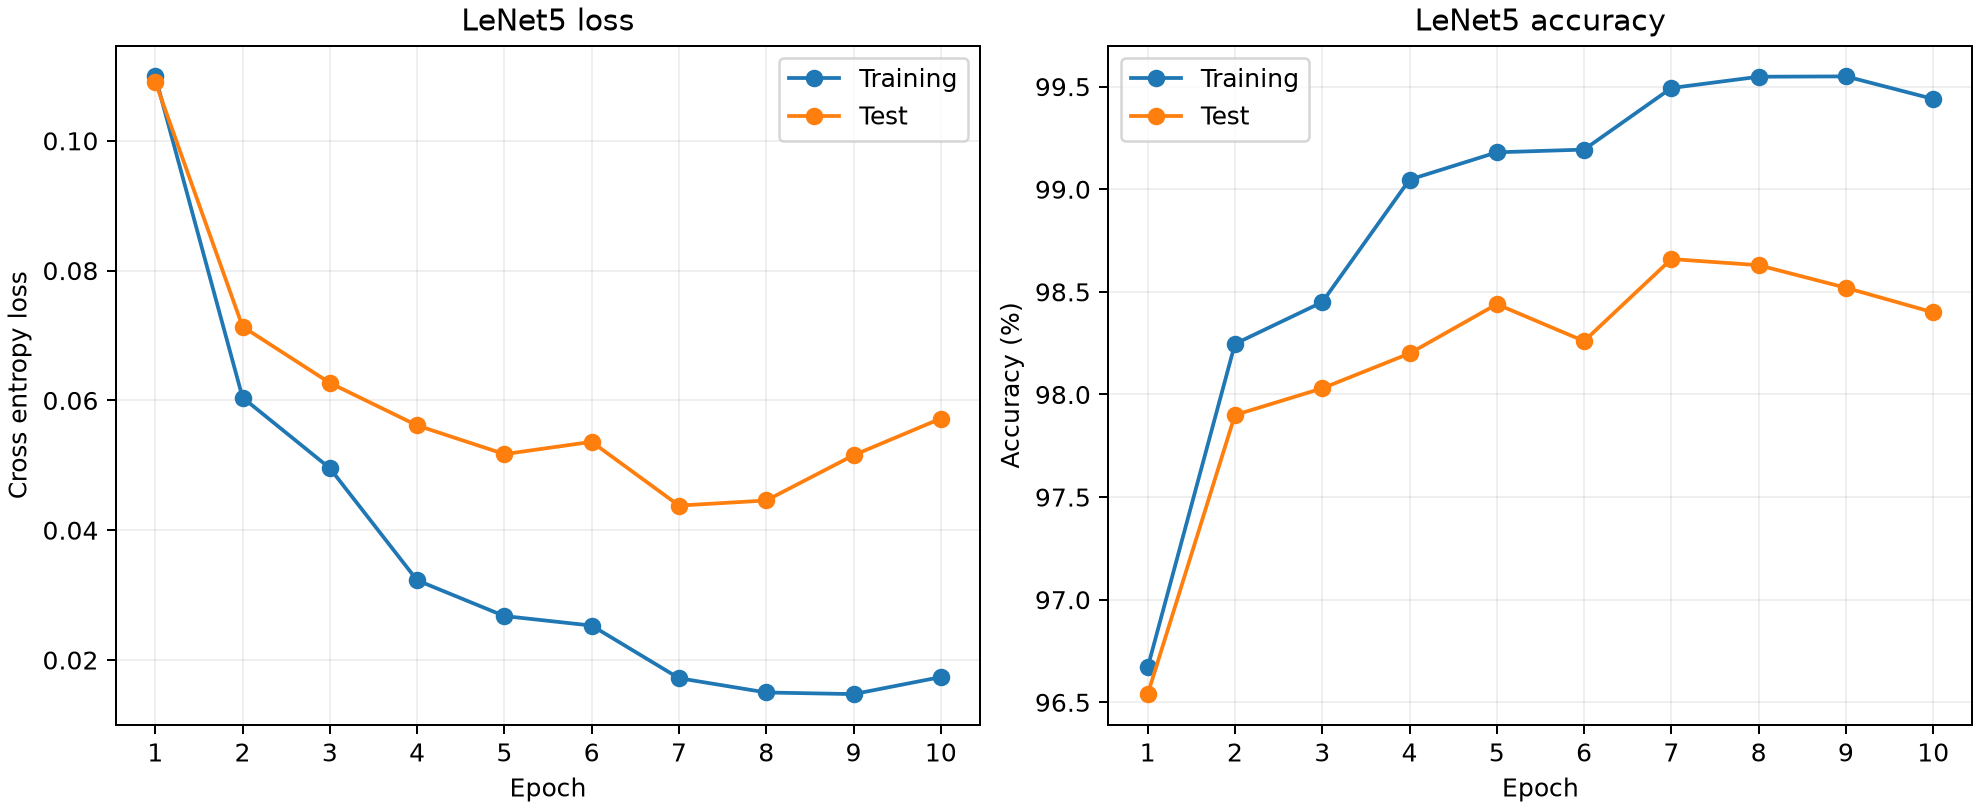

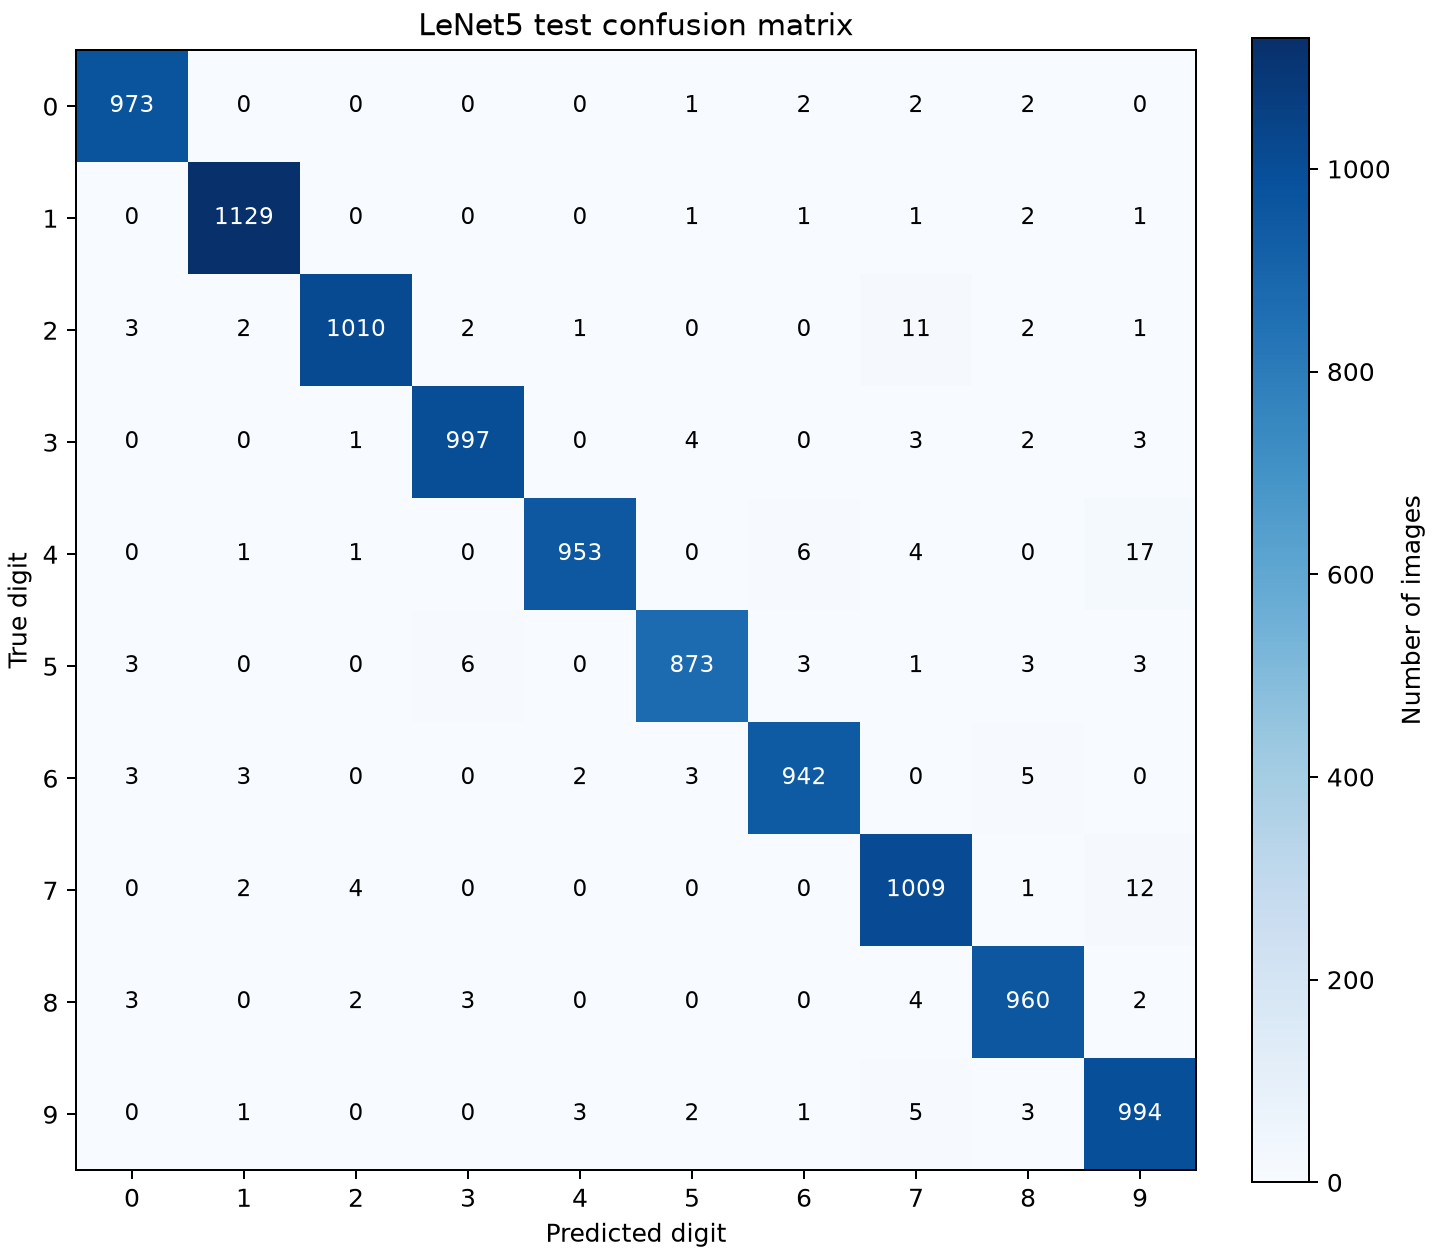

In [15]:
lenet_final = lenet_result["final_metrics"]
print(f"Training accuracy: {lenet_final['train_accuracy']:.2f}%")
print(f"Test accuracy: {lenet_final['test_accuracy']:.2f}%")
display(Image(filename=str(ROOT / "results/q2_lenet/training_curve.png"), width=900))
display(Image(filename=str(ROOT / "results/q2_lenet/confusion_matrix.png"), width=650))


After 10 epochs the training accuracy is 99.44% and the test accuracy is 98.40%. Both training and test loss are lower at the end than at the first epoch. The test loss rises in the final epochs, suggesting some overfitting

The confusion matrix has true digits on the rows and predicted digits on the columns. The largest error count is 17 images of digit 4 predicted as 9

### QUESTION 2(B)  SMALL CNN

The small CNN has three convolution layers with 8, 16 and 32 output channels. Each layer uses batch normalization, ReLU and max pooling. A fully connected layer with 64 units is followed by dropout with probability 0.25 and the final 10 output scores

The data, padding, batch size, Adam optimizer, learning rate, random seed and ten epoch training schedule are the same as the LeNet5 experiment

In [16]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


ROOT = Path.cwd()


from IPython.display import Image, display


#### NETWORK

In [17]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, 10),
        )

    def forward(self, inputs):
        return self.classifier(self.features(inputs))


#### DATA AND EVALUATION

In [18]:
def create_cnn_loaders(batch_size=50, seed=0):
    transform = transforms.Compose([transforms.Pad(padding=2), transforms.ToTensor()])
    trainset = datasets.MNIST(
        root=ROOT / "data", train=True, download=True, transform=transform
    )
    testset = datasets.MNIST(
        root=ROOT / "data", train=False, download=True, transform=transform
    )
    generator = torch.Generator().manual_seed(seed)
    trainloader = DataLoader(
        trainset, batch_size=batch_size, shuffle=True, generator=generator, num_workers=0
    )
    train_eval_loader = DataLoader(trainset, batch_size=batch_size, num_workers=0)
    testloader = DataLoader(testset, batch_size=batch_size, num_workers=0)
    return trainloader, train_eval_loader, testloader

@torch.no_grad()
def evaluate_cnn(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    confusion = torch.zeros((10, 10), dtype=torch.int64)
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * len(labels)
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += len(labels)
        pairs = labels.cpu() * 10 + predictions.cpu()
        confusion += torch.bincount(pairs, minlength=100).reshape(10, 10)
    return total_loss / total, 100.0 * correct / total, confusion


#### LEARNING CURVES AND CONFUSION MATRIX

In [19]:
def save_cnn_history(history, settings, output_dir):
    output_dir.mkdir(parents=True, exist_ok=True)
    with (output_dir / "history.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    cnn_result = {
        **settings,
        "completed_epochs": len(history),
        "final_metrics": history[-1],
        "history": history,
    }
    (output_dir / "training_results.json").write_text(
        json.dumps(cnn_result, indent=2) + "\n", encoding="utf-8"
    )

    epochs = [row["epoch"] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
    axes[0].plot(epochs, [row["train_loss"] for row in history], marker="o", label="Training")
    axes[0].plot(epochs, [row["test_loss"] for row in history], marker="o", label="Test")
    axes[0].set(xlabel="Epoch", ylabel="Cross entropy loss", title="Small CNN loss")
    axes[1].plot(epochs, [row["train_accuracy"] for row in history], marker="o", label="Training")
    axes[1].plot(epochs, [row["test_accuracy"] for row in history], marker="o", label="Test")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Small CNN accuracy")
    for axis in axes:
        axis.set_xticks(epochs)
        axis.grid(alpha=0.2)
        axis.legend()
    fig.savefig(output_dir / "training_curve.png", dpi=180)
    plt.close(fig)
    return cnn_result

def save_cnn_confusion(confusion, output_dir):
    matrix = confusion.tolist()
    (output_dir / "confusion_matrix.json").write_text(
        json.dumps({"rows": "True digit", "columns": "Predicted digit", "counts": matrix}, indent=2)
        + "\n",
        encoding="utf-8",
    )
    with (output_dir / "confusion_matrix.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(["True digit"] + list(range(10)))
        writer.writerows([[digit] + row for digit, row in enumerate(matrix)])

    fig, axis = plt.subplots(figsize=(8, 7), layout="constrained")
    image = axis.imshow(confusion.numpy(), cmap="Blues")
    fig.colorbar(image, ax=axis, label="Number of images")
    axis.set(
        xticks=range(10),
        yticks=range(10),
        xlabel="Predicted digit",
        ylabel="True digit",
        title="Small CNN test confusion matrix",
    )
    threshold = confusion.max().item() / 2
    for row in range(10):
        for column in range(10):
            value = matrix[row][column]
            axis.text(
                column,
                row,
                str(value),
                ha="center",
                va="center",
                color="white" if value > threshold else "black",
                fontsize=9,
            )
    fig.savefig(output_dir / "confusion_matrix.png", dpi=180)
    plt.close(fig)


#### TRAINING

In [20]:
def train_small_cnn(epochs=10, batch_size=50, learning_rate=0.001, seed=0, verbose=True):
    if epochs < 1 or batch_size < 1 or learning_rate <= 0:
        raise ValueError("Invalid training settings")
    torch.set_num_threads(4)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)
    device = torch.device("cpu")
    trainloader, train_eval_loader, testloader = create_cnn_loaders(batch_size, seed)
    model = SmallCNN().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    output_dir = ROOT / "results" / "q2_cnn"
    history = []
    settings = {
        "model": "Small CNN",
        "dataset": "MNIST",
        "training_samples": len(trainloader.dataset),
        "test_samples": len(testloader.dataset),
        "input_shape": [1, 32, 32],
        "input_padding": 2,
        "pixel_range": [0, 1],
        "augmentation": False,
        "activation": "relu",
        "pooling": "max",
        "batch_normalization": True,
        "dropout": 0.25,
        "convolution_channels": [1, 8, 16, 32],
        "convolution_kernel_size": 3,
        "classifier_sizes": [512, 64, 10],
        "output": "logits",
        "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
        "loss": "cross entropy",
        "optimizer": "Adam",
        "learning_rate": learning_rate,
        "epochs": epochs,
        "batch_size": batch_size,
        "seed": seed,
        "device": str(device),
        "torch_threads": 4,
        "training_shuffle": True,
        "epoch_metrics": "Full training and test sets evaluated after each epoch",
        "accuracy_units": "percent",
    }
    for epoch in range(1, epochs + 1):
        model.train()
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Training loss is not finite")
            loss.backward()
            optimizer.step()
        train_loss, train_accuracy, _ = evaluate_cnn(model, train_eval_loader, criterion, device)
        test_loss, test_accuracy, confusion = evaluate_cnn(model, testloader, criterion, device)
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "train_accuracy": train_accuracy,
                "test_loss": test_loss,
                "test_accuracy": test_accuracy,
            }
        )
        cnn_result = save_cnn_history(history, settings, output_dir)
        if verbose:
            print(
                f"Epoch {epoch} of {epochs}: training accuracy {train_accuracy:.2f}%, "
                f"test accuracy {test_accuracy:.2f}%, training loss {train_loss:.4f}, "
                f"test loss {test_loss:.4f}",
                flush=True,
            )

    save_cnn_confusion(confusion, output_dir)
    torch.save(
        {"model_state_dict": model.state_dict(), "settings": settings},
        output_dir / "cnn_weights.pt",
    )
    return cnn_result


In [21]:
cnn_result = train_small_cnn(verbose=False)


#### RESULTS

Training accuracy: 99.50%
Test accuracy: 98.82%


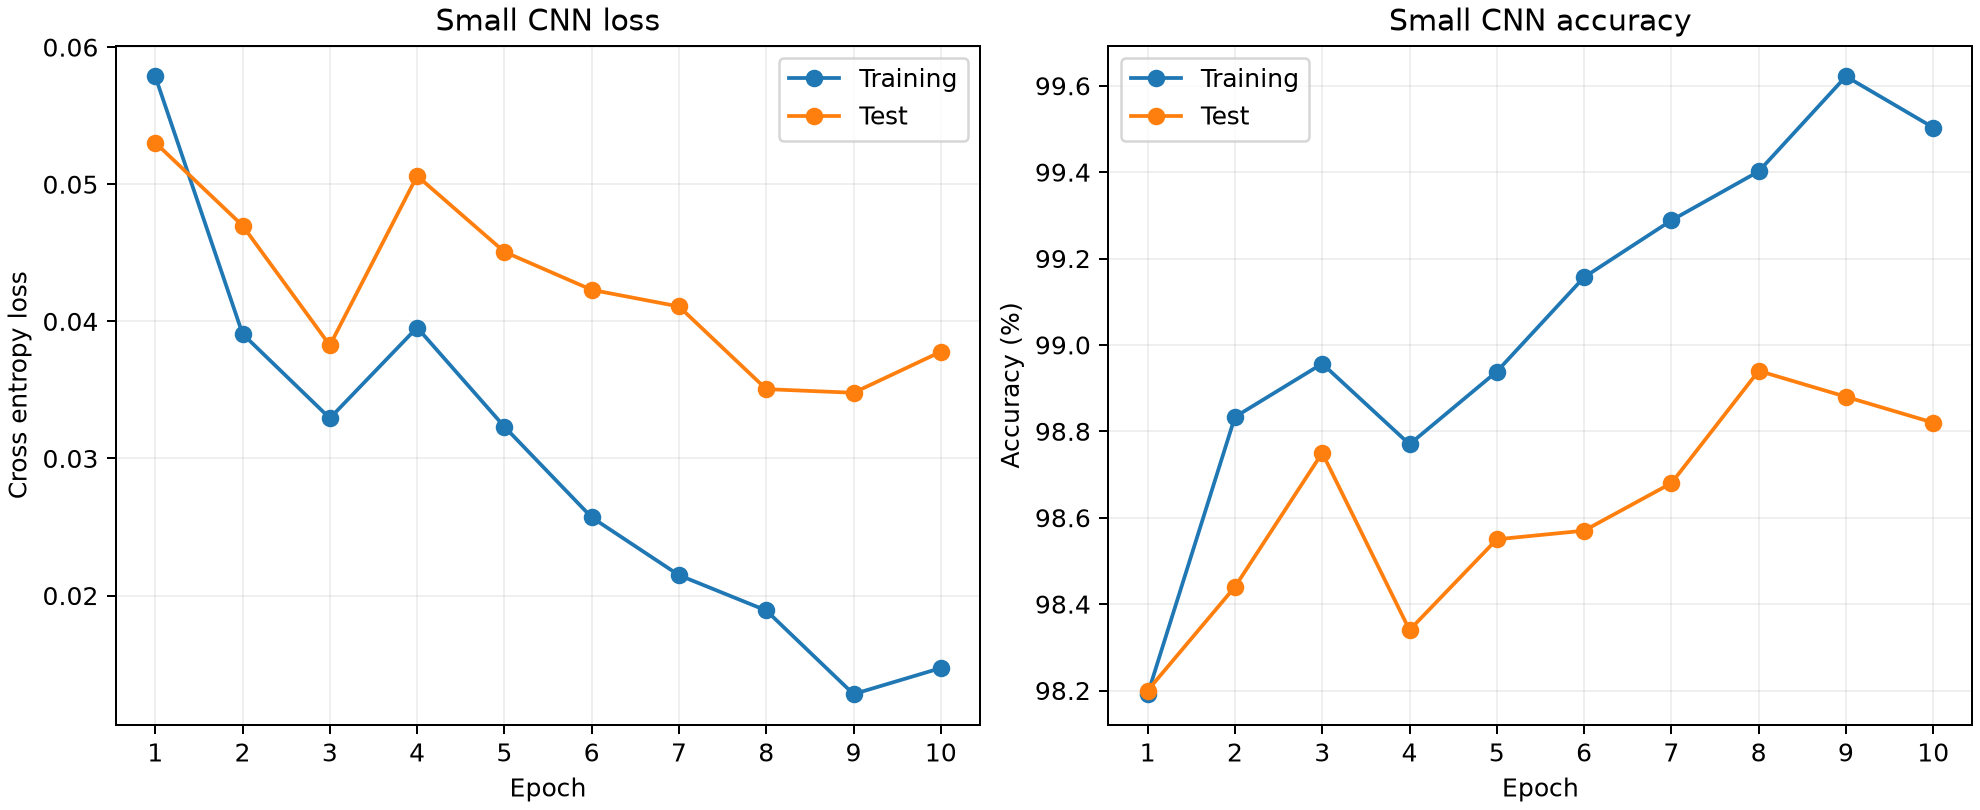

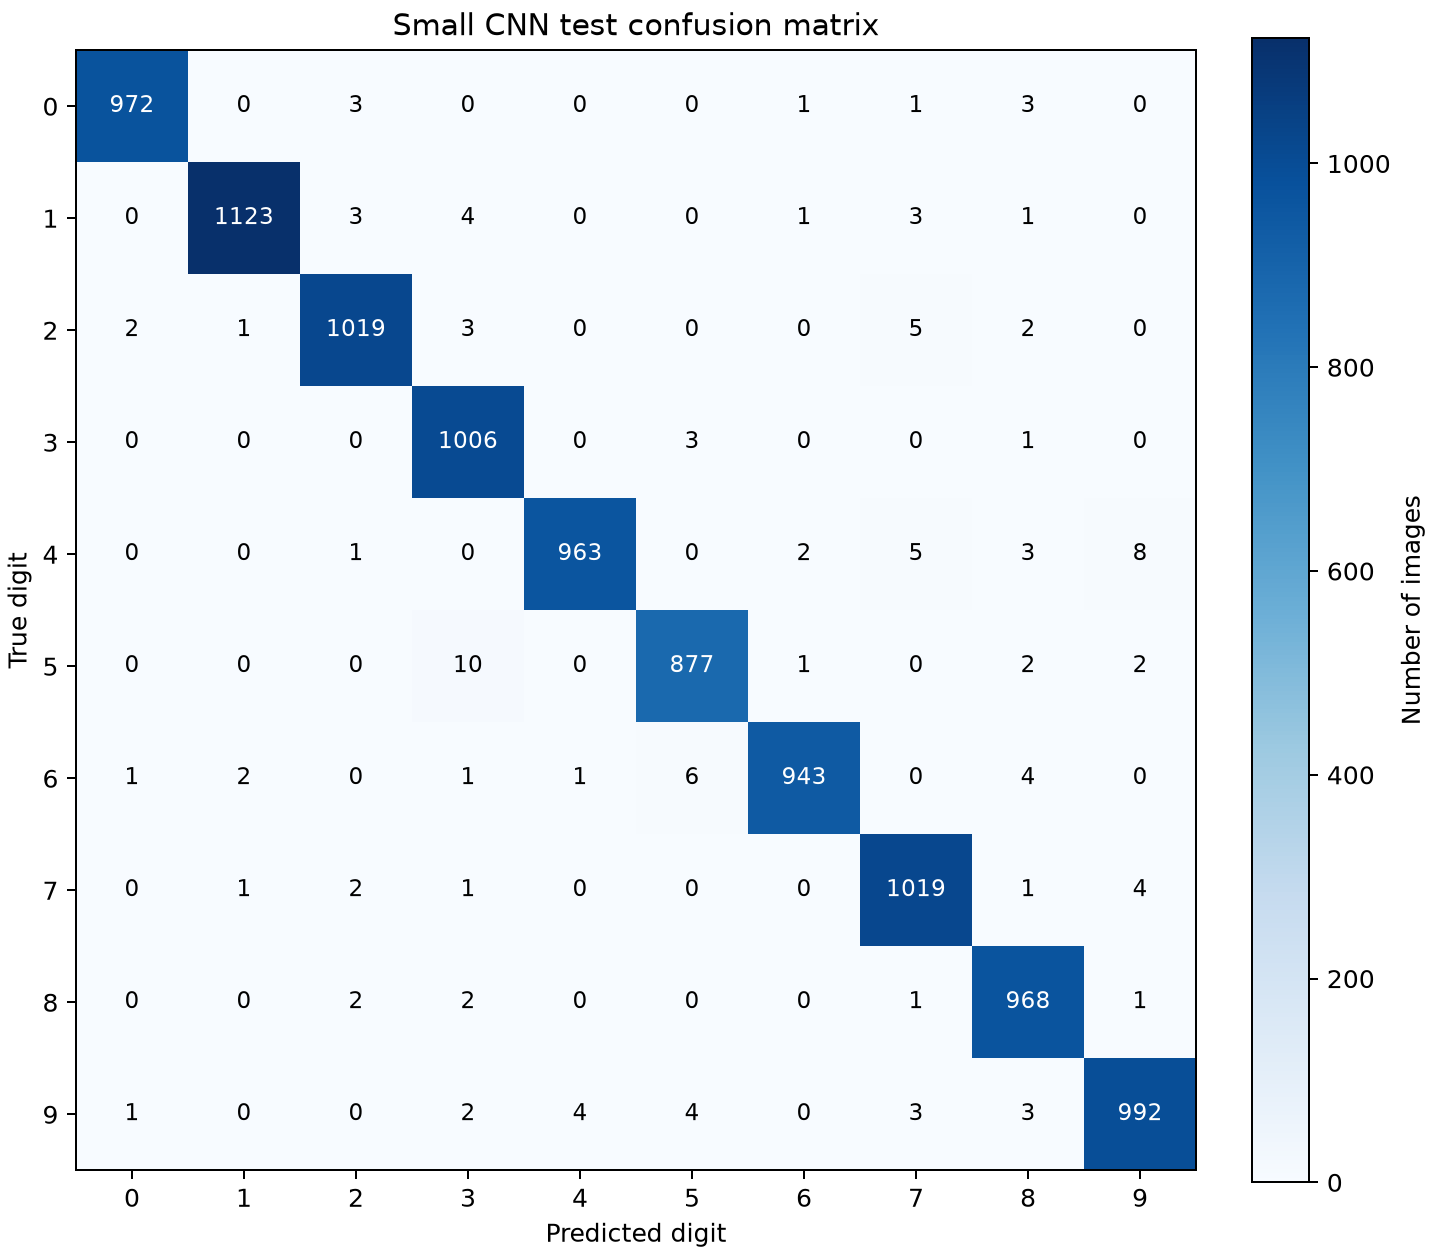

In [22]:
cnn_final = cnn_result["final_metrics"]
print(f"Training accuracy: {cnn_final['train_accuracy']:.2f}%")
print(f"Test accuracy: {cnn_final['test_accuracy']:.2f}%")
display(Image(filename=str(ROOT / "results/q2_cnn/training_curve.png"), width=900))
display(Image(filename=str(ROOT / "results/q2_cnn/confusion_matrix.png"), width=650))


After 10 epochs the training accuracy is 99.50% and the test accuracy is 98.82%. For this run the small CNN test accuracy is 0.42 percentage points higher than LeNet5

The confusion matrix uses the same test set as LeNet5. Its largest error count is 10 images of digit 5 predicted as 3